# Cases and scalability: HDB resale transactions

**Goal:** for the HDB data, starting from the settings chosen in `11_data_gov_hdb_resale_clustering.ipynb`:

1. Which cases succeed or fail, and why?
2. How does runtime grow with the number of sales?
3. How does HDB compare with the other datasets?

**Input:** the same 20,000 sales (seed 0) and the two data versions as `11_data_gov_hdb_resale_clustering.ipynb`:
real (values as recorded) and jittered (`jitter_ties`). Chosen settings: K-means++ K=4; DBSCAN and HDBSCAN as
selected by the project rule (section 4 and 5 of that notebook).

**Terms** (as in `11_data_gov_hdb_resale_clustering.ipynb`, plus)

| Term | Meaning |
|---|---|
| single-band cluster | A cluster whose sales all lie in one storey band, a sign that it is a tie rather than a group of similar flats |
| log-log slope | The exponent b in runtime ≈ a × n^b, fitted on log runtime against log n; 1 means runtime doubles when n doubles |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.neighbors import NearestNeighbors

from sc4020 import methods, run, tuning
from sc4020.datasets import load_dataset
from sc4020.metrics import (
    cluster_shares,
)
from sc4020.paths import results_dir

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

SEED = 0
SAMPLE_SIZE = 20_000
SILHOUETTE_SAMPLE = 5_000
RESULTS = results_dir("hdb_resale")
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)
comparison = pd.read_csv(RESULTS / "comparison.csv")

## 1. Comparison table at the chosen settings

In [2]:
comparison[
    [
        "method",
        "data",
        "params",
        "n_clusters",
        "noise_fraction",
        "largest_cluster_share",
        "silhouette",
        "null_silhouette",
        "davies_bouldin",
        "ari",
        "nmi",
        "single_storey_clusters",
        "fit_seconds",
    ]
]

,method,data,params,n_clusters,noise_fraction,largest_cluster_share,silhouette,null_silhouette,davies_bouldin,ari,nmi,single_storey_clusters,fit_seconds
0,K-means++,real,K=4,4,0.000,0.351,0.317,0.218,1.116,0.213,0.293,0,0.010
1,DBSCAN,real,"eps=0.567, min_samples=10",3,0.014,0.971,0.239,0.330,0.732,0.030,0.091,1,0.428
2,DBSCAN,jittered,"eps=0.661, min_samples=5",2,0.003,0.997,0.494,0.289,0.437,0.001,0.001,0,0.519
3,HDBSCAN,real,"min_cluster_size=200, min_samples=None",2,0.285,0.686,0.160,0.593,1.133,0.072,0.101,0,2.009
4,HDBSCAN,jittered,"min_cluster_size=200, min_samples=None",2,0.274,0.698,0.150,0.565,1.119,0.069,0.096,0,1.997
5,GMM,real,"n_components=12, covariance_type=full",12,0.000,0.141,0.140,0.056,1.849,0.207,0.385,0,1.127
6,Spectral,real,"K=4, affinity=nearest_neighbors",4,0.000,0.398,0.065,-0.009,2.237,0.034,0.078,0,0.341


**Observations**

- The table repeats `11_data_gov_hdb_resale_clustering.ipynb` (`results/comparison.csv`).
- The density methods at the rule's settings put most sales in one cluster: DBSCAN 97.1% (real) and 99.7% (jittered), HDBSCAN 68.6% and 69.8%.
- ARI against flat type is at most 0.213 (K-means++).

## 2. Success and failure cases

Each case names the figure that shows it and the data property behind it.

In [3]:
cases = pd.DataFrame(
    [
        {
            "case": "K-means finds 4 market segments",
            "outcome": "success",
            "cause": "continuous features with weak but real joint structure (silhouette 1.45x null)",
            "figure": "figures/kmeans_clusters.png",
        },
        {
            "case": "Density settings chosen by the rule put 97% to 99.7% in one cluster",
            "outcome": "failure",
            "cause": "density: one dense core with no gaps; silhouette rewards a giant plus a tiny cluster",
            "figure": "figures/comparison.png",
        },
        {
            "case": "HDBSCAN finds new 3 ROOM flats as a compact group",
            "outcome": "success",
            "cause": "density: a standard flat design sold at one lease age forms a real dense spot",
            "figure": "figures/comparison.png",
        },
        {
            "case": "No method recovers flat type from all four features",
            "outcome": "failure",
            "cause": "label defined by one feature (floor area); price and storey cut across it",
            "figure": "figures/kmeans_k_sweep.png",
        },
    ]
)
cases.to_csv(RESULTS / "cases.csv", index=False)
cases

,case,outcome,cause,figure
0,K-means finds 4 market segments,success,continuous features with weak but real joint s...,figures/kmeans_clusters.png
1,Density settings chosen by the rule put 97% to...,failure,density: one dense core with no gaps; silhouet...,figures/comparison.png
2,HDBSCAN finds new 3 ROOM flats as a compact group,success,density: a standard flat design sold at one le...,figures/comparison.png
3,No method recovers flat type from all four fea...,failure,label defined by one feature (floor area); pri...,figures/kmeans_k_sweep.png


**Observations**

- 2 successes and 2 failures, each with a named cause and figure. The failures come from one dense core with no gaps and from a label defined by one feature (floor area); the successes come from continuous joint structure (K-means segments) and a real dense product (new 3 ROOM flats).

## 3. Scalability

Random subsets of all 234,294 sales (standardized on all sales, ties jittered as in `load_hdb_resale`), each method at
the setting the shared rule chooses on the default 20,000-sale sample (density methods capped at max(K range) clusters).
K-means++ runs with one start (n_init=1). Sizes up to 20,000 run 3 times (median shown); larger sizes once. Slopes are fitted on sizes
of 5,000 and above, where fixed overheads matter less. Runtimes depend on the machine (Apple M2, 16 GB).

DBSCAN stores every neighbour within eps for every point. Before each DBSCAN run the number of neighbour pairs
is estimated from 2,000 probe points; runs above `MAX_NEIGHBOUR_PAIRS` are recorded as skipped, to stay within
16 GB of memory. `scalability.csv` is saved after every run, so progress survives an interruption (about 5 minutes).

In [4]:
SCALABILITY_SIZES = (
    1_000,
    2_000,
    5_000,
    10_000,
    20_000,
    50_000,
    100_000,
    None,
)  # None: all sales
REPEATS_UP_TO = 20_000  # sizes up to this run 3 times; larger sizes once
MAX_NEIGHBOUR_PAIRS = (
    150_000_000  # DBSCAN stores neighbourhoods as int64 indices: about 1.2 GB
)
PROBE_POINTS = 2_000

k_range = run.K_RANGES.get("hdb_resale", tuning.K_RANGE)
scalability_settings = run.select_params(
    load_dataset("hdb_resale"),
    ["K-Means", "DBSCAN", "HDBSCAN"],
    k_range,
    max_clusters=max(k_range),
)
scalability_k = scalability_settings["K-Means"].params["n_clusters"]
scalability_dbscan = scalability_settings["DBSCAN"].params
scalability_hdbscan = scalability_settings["HDBSCAN"].params
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    all_sales_X = load_dataset("hdb_resale", n_samples=None, random_state=SEED).data
print(
    f"{len(all_sales_X):,} sales; K={scalability_k}; DBSCAN {scalability_dbscan}; "
    f"HDBSCAN {scalability_hdbscan}"
)

/Users/weiyew/Documents/SC4020/SC4020-Project-1/src/sc4020/datasets/load_dataset.py:530: UserWarning: Dropped 6051 sales without a price index value (months 2026-07 to 2026-09)
  features = pp.hdb_features(sales, price_index)


234,294 sales; K=4; DBSCAN {'eps': 0.5081347502247469, 'min_samples': 8}; HDBSCAN {'min_cluster_size': 400, 'min_samples': 5}


In [5]:
def estimated_neighbour_pairs(X, eps, rng):
    """Neighbour pairs within eps over all of X, estimated from PROBE_POINTS probe points."""
    probe = X[rng.choice(len(X), size=min(PROBE_POINTS, len(X)), replace=False)]
    counts = (
        NearestNeighbors(radius=eps)
        .fit(X)
        .radius_neighbors(probe, return_distance=False)
    )
    return float(np.mean([len(c) for c in counts]) * len(X))


model_makers = {
    "K-Means": lambda: methods.kmeans(scalability_k, n_init=1, random_state=SEED),
    "DBSCAN": lambda: methods.dbscan(**scalability_dbscan),
    "HDBSCAN": lambda: methods.hdbscan(**scalability_hdbscan),
}
scalability_path = RESULTS / "scalability.csv"
scalability_rows = []
rng = np.random.default_rng(SEED)
for size in SCALABILITY_SIZES:
    n = len(all_sales_X) if size is None else size
    X_subset = all_sales_X[np.sort(rng.choice(len(all_sales_X), size=n, replace=False))]
    for method, make_model in model_makers.items():
        base = {"method": method, "n": n}
        if method == "DBSCAN":
            pairs = estimated_neighbour_pairs(
                X_subset, scalability_dbscan["eps"], np.random.default_rng(SEED)
            )
            base["estimated_neighbour_pairs"] = pairs
            if pairs > MAX_NEIGHBOUR_PAIRS:
                scalability_rows.append(
                    {**base, "skipped": f"estimated {pairs:,.0f} neighbour pairs"}
                )
                pd.DataFrame(scalability_rows).to_csv(scalability_path, index=False)
                print(f"{method} n={n}: skipped ({pairs:,.0f} neighbour pairs)")
                continue
        for repeat in range(3 if n <= REPEATS_UP_TO else 1):
            labels, seconds = methods.fit_predict_timed(make_model(), X_subset)
            scalability_rows.append(
                {
                    **base,
                    "repeat": repeat,
                    "fit_seconds": seconds,
                    **cluster_shares(labels),
                }
            )
            pd.DataFrame(scalability_rows).to_csv(scalability_path, index=False)
            print(f"{method} n={n} repeat {repeat}: {seconds:.2f} s")

K-Means n=1000 repeat 0: 0.00 s
K-Means n=1000 repeat 1: 0.00 s
K-Means n=1000 repeat 2: 0.00 s
DBSCAN n=1000 repeat 0: 0.00 s
DBSCAN n=1000 repeat 1: 0.00 s
DBSCAN n=1000 repeat 2: 0.00 s
HDBSCAN n=1000 repeat 0: 0.01 s
HDBSCAN n=1000 repeat 1: 0.01 s
HDBSCAN n=1000 repeat 2: 0.01 s
K-Means n=2000 repeat 0: 0.01 s
K-Means n=2000 repeat 1: 0.01 s
K-Means n=2000 repeat 2: 0.01 s
DBSCAN n=2000 repeat 0: 0.01 s
DBSCAN n=2000 repeat 1: 0.01 s
DBSCAN n=2000 repeat 2: 0.01 s
HDBSCAN n=2000 repeat 0: 0.02 s
HDBSCAN n=2000 repeat 1: 0.02 s
HDBSCAN n=2000 repeat 2: 0.02 s
K-Means n=5000 repeat 0: 0.01 s
K-Means n=5000 repeat 1: 0.01 s
K-Means n=5000 repeat 2: 0.00 s


DBSCAN n=5000 repeat 0: 0.04 s
DBSCAN n=5000 repeat 1: 0.04 s
DBSCAN n=5000 repeat 2: 0.04 s
HDBSCAN n=5000 repeat 0: 0.10 s


HDBSCAN n=5000 repeat 1: 0.09 s
HDBSCAN n=5000 repeat 2: 0.09 s
K-Means n=10000 repeat 0: 0.01 s
K-Means n=10000 repeat 1: 0.01 s
K-Means n=10000 repeat 2: 0.01 s


DBSCAN n=10000 repeat 0: 0.12 s
DBSCAN n=10000 repeat 1: 0.11 s


DBSCAN n=10000 repeat 2: 0.11 s


...

HDBSCAN n=50000 repeat 0: 8.07 s
K-Means n=100000 repeat 0: 0.03 s


DBSCAN n=100000 repeat 0: 5.18 s


HDBSCAN n=100000 repeat 0: 30.83 s
K-Means n=234294 repeat 0: 0.07 s


DBSCAN n=234294: skipped (567,719,783 neighbour pairs)


HDBSCAN n=234294 repeat 0: 163.39 s


In [6]:
scalability = pd.read_csv(scalability_path)
if "skipped" in scalability.columns:
    skipped = scalability[scalability["skipped"].notna()]
    print("skipped runs:")
    print(
        skipped[["method", "n", "skipped"]].to_string(index=False)
        if len(skipped)
        else "none"
    )
    timed = scalability[scalability["skipped"].isna()]
else:
    timed = scalability
runtime = (
    timed.groupby(["method", "n"])
    .agg(
        seconds=("fit_seconds", "median"),
        n_clusters=("n_clusters", "median"),
        noise_fraction=("noise_fraction", "median"),
        largest=("largest_cluster_share", "median"),
    )
    .reset_index()
)

slopes = {}
for method, part in runtime[runtime["n"] >= 5_000].groupby("method"):
    if len(part) >= 2:
        slopes[method] = np.polyfit(np.log(part["n"]), np.log(part["seconds"]), 1)[0]
display(runtime.pivot(index="n", columns="method", values="seconds"))
display(pd.Series(slopes, name="log-log slope (n ≥ 5,000)").to_frame())
runtime.to_csv(RESULTS / "scalability_summary.csv", index=False)

skipped runs:
method      n                               skipped
DBSCAN 234294 estimated 567,719,783 neighbour pairs


method,DBSCAN,HDBSCAN,K-Means
n,,,
1000,0.004,0.006,0.002
2000,0.010,0.018,0.007
5000,0.038,0.088,0.006
10000,0.114,0.340,0.005
20000,0.350,1.347,0.007
50000,1.584,8.072,0.015
100000,5.179,30.833,0.025
234294,NaN,163.386,0.068


,"log-log slope (n ≥ 5,000)"
DBSCAN,1.638
HDBSCAN,1.956
K-Means,0.671


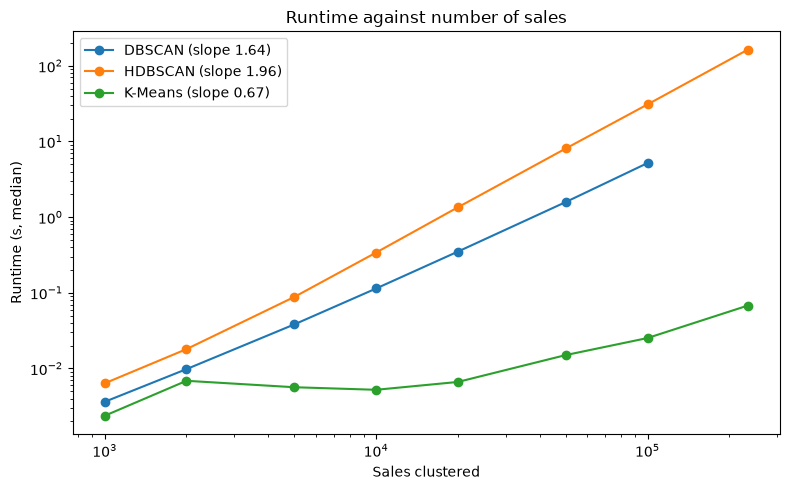

PosixPath('/Users/weiyew/Documents/SC4020/SC4020-Project-1/results/hdb_resale/figures/scalability.png')

In [7]:
from sc4020.generate_figures import show_and_save_to

fig, ax = plt.subplots(figsize=(8, 5))
for method, part in runtime.groupby("method"):
    label = f"{method} (slope {slopes[method]:.2f})" if method in slopes else method
    ax.plot(part["n"], part["seconds"], "o-", label=label)
ax.set(
    xscale="log",
    yscale="log",
    xlabel="Sales clustered",
    ylabel="Runtime (s, median)",
    title="Runtime against number of sales",
)
ax.legend()
fig.tight_layout()
show_and_save_to(fig, FIGURES / "scalability.png")

**Observations**

- The settings here come from `run.select_params` on the loader's default sample: DBSCAN eps 0.508 and `min_samples` 8, HDBSCAN `min_cluster_size` 400 and `min_samples` 5. They differ from the settings chosen in `11_data_gov_hdb_resale_clustering.ipynb`, so the runtimes describe growth, not the exact chosen runs.
- **K-means++** stays under 0.07 s up to all 234,294 sales (slope 0.67). At these times fixed overheads dominate, so the slope is not the algorithm's growth.
- **DBSCAN** grows with slope 1.64: 0.35 s at 20,000 and 5.2 s at 100,000. At all 234,294 sales it was **skipped for memory, not time**: an estimated 568 million neighbour pairs within eps would need about 4.5 GB for the neighbour indices alone (8 bytes each), on a 16 GB machine.
- **HDBSCAN** grows with slope 1.96: 1.35 s at 20,000, 30.8 s at 100,000 and 163 s at all sales.
- On earthquakes (500 to 7,643 points, `09_usgs_earthquakes_2023_cases.ipynb`) the HDBSCAN slope is 1.75.

## 4. Cross-dataset comparison

Chosen settings on each dataset, from `results/earthquakes_2023/cross_dataset_comparison.csv` (earthquakes and
LTA) and this project's `results/comparison.csv` (HDB, real data). Each dataset uses its own features and
distance, so silhouettes compare how clear the structure is within each dataset, not across them.

In [8]:
other = pd.read_csv(results_dir("earthquakes_2023") / "cross_dataset_comparison.csv")
hdb_rows = comparison[comparison["data"] == "real"].assign(dataset="HDB resale")[
    other.columns.drop("fit_seconds").tolist() + ["fit_seconds"]
]
cross = pd.concat([other, hdb_rows], ignore_index=True)
cross.to_csv(RESULTS / "cross_dataset_comparison.csv", index=False)
cross

,dataset,method,params,n_clusters,noise_fraction,largest_cluster_share,silhouette,null_silhouette,davies_bouldin,fit_seconds
0,earthquakes,K-means++,"K=6, n_init=1",6.0,0.000,0.310,0.529,0.390,0.738,5.649e-03
1,earthquakes,DBSCAN,"eps=101.8 km, min_samples=20",41.0,0.404,0.118,0.703,NaN,0.351,5.210e-02
2,earthquakes,HDBSCAN,"min_cluster_size=50, min_samples=default",28.0,0.307,0.075,0.758,0.320,0.329,1.089e+00
3,earthquakes,GMM,"n_components=12, covariance_type=full",12.0,0.000,0.167,0.442,0.352,0.907,4.058e-01
4,earthquakes,Spectral,"K=6, affinity=nearest_neighbors",6.0,0.000,0.316,0.333,0.320,0.914,8.938e-02
5,LTA train,K-means (random),"K=4, n_init=1",4.0,0.000,0.486,0.260,0.067,1.313,1.539e-03
6,LTA train,K-means++,"K=4, n_init=1",4.0,0.000,0.481,0.257,0.066,1.332,7.653e-04
7,LTA train,DBSCAN,"eps=0.0686 (p75), min_samples=5",2.0,0.135,0.816,0.487,NaN,0.595,1.226e-03
8,LTA train,HDBSCAN,"min_cluster_size=5, min_samples=default",2.0,0.416,0.551,0.497,NaN,0.533,3.156e-03
9,LTA bus,K-means (random),"K=5, n_init=1",5.0,0.000,0.299,0.204,0.082,1.483,1.490e-02


**Observations**

- **HDB is the only dataset where the density rule's settings score below the shuffled null** (DBSCAN 0.239 vs 0.330, HDBSCAN 0.160 vs 0.593). Earthquake HDBSCAN scores 0.758 vs 0.320. For LTA and earthquake DBSCAN no null silhouette was recorded.
- K-means silhouette relative to its null: earthquakes 1.36x (0.529 vs 0.390), LTA train 3.9x (0.260 vs 0.067), HDB 1.45x (0.317 vs 0.218), using the K-means++ null for LTA train. LTA bus is 2.5x for random init and 1.5x for K-means++, because the null differs between the two rows.

## 5. Key factors and summary

**Key factors.** The data properties that most change how the methods rank on HDB:

| Factor | Evidence | Effect |
|---|---|---|
| No gaps between groups | Density settings chosen by the rule put 97.1% to 99.7% of sales in one cluster, and their silhouettes are below the shuffled null (section 1) | Density methods return one dominant cluster; Spectral finds close to no structure (silhouette 0.065, ARI 0.034) |
| Ties from recorded values | At fine density settings 128 of 128 DBSCAN and 38 of 41 HDBSCAN clusters are single storey bands (`11_data_gov_hdb_resale_clustering.ipynb`, sections 4 and 5) | Density methods find recording steps, not groups |
| Label definition | Floor area alone matches flat type at ARI 0.649; all four features at most 0.256 over the K-means K sweep | ARI against flat type measures floor area |
| Size | DBSCAN skipped at 234,294 sales for memory; HDBSCAN 163 s (section 3) | K-means++ is the only method run at full size at no cost |

**What this gives the report (HDB's role).** Real data with labels where internal metrics mislead: the silhouette favours giant-plus-tiny density partitions, and ARI against flat type measures floor area. K-means++ gives 4 market segments; GMM matches it on ARI (0.207 against 0.213); Spectral and the density methods find little.